In [1]:
import os
import keras
import math
import glob
import time
import random
import pickle
import numpy as np
import pandas as pd
import seaborn as sns
from tqdm import tqdm
import tensorflow as tf
from keras.layers import *
from keras.optimizers import *
from keras import backend as K
from keras.models import Model
import matplotlib.pyplot as plt
from scipy.signal import medfilt
from collections import defaultdict
from scipy.spatial.distance import cdist
from tensorflow.keras import backend as K
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam
import scipy.ndimage.interpolation as inter
from tensorflow.keras.models import load_model
from sklearn.preprocessing import LabelEncoder
from tensorflow.keras.callbacks import TensorBoard
from tensorflow.keras.layers import Reshape, Flatten
from sklearn.model_selection import KFold, StratifiedKFold
from tensorflow.keras.layers import BatchNormalization, Dropout
from tensorflow.keras.callbacks import ModelCheckpoint, ReduceLROnPlateau
from sklearn.metrics import (
    confusion_matrix, accuracy_score, precision_score,
    recall_score, f1_score, roc_auc_score, roc_curve
)
from sklearn.preprocessing import label_binarize
from tensorflow.keras.layers import Input, Dense, Dropout, Conv2D, Conv2DTranspose, GlobalMaxPool2D

2025-04-25 11:10:21.237407: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2025-04-25 11:10:21.256115: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:477] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1745597421.278705  889069 cuda_dnn.cc:8310] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1745597421.282653  889069 cuda_blas.cc:1418] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2025-04-25 11:10:21.310827: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instr

In [2]:
random.seed(1234)

class Config():
    def __init__(self):
        self.frame_l = 64 # the length of frames
        self.joint_n = 33 # the number of joints
        self.joint_d = 3 # the dimension of joints
        self.clc = 3 # the number of coarse class
        self.feat_d = 528
        self.filters = 64
        self.num_folds = 5
        self.data_dir = r"/home/nyam/Ms_Thesis/Autism/Project_v3/Stimming/DataProcessing/v2/skel_clean_aug"
        self.dataset_info = r"/home/nyam/Ms_Thesis/Autism/Project_v3/Stimming/DataProcessing/v2/dataset_info_clean_aug.txt"
C = Config()

In [3]:
#Rescale to be 64 frames
def zoom(p,target_l=64,joints_num=33,joints_dim=3):
    l = p.shape[0]
    p_new = np.empty([target_l,joints_num,joints_dim])
    for m in range(joints_num):
        for n in range(joints_dim):
            p[:,m,n] = medfilt(p[:,m,n],3)
            p_new[:,m,n] = inter.zoom(p[:,m,n],target_l/l)[:target_l]
    return p_new

def normlize_range(p):
    # normolize to start point, use the center for hand case
    p[:,:,0] = p[:,:,0]-np.mean(p[:,:,0])
    p[:,:,1] = p[:,:,1]-np.mean(p[:,:,1])
    p[:,:,2] = p[:,:,2]-np.mean(p[:,:,2])
    return p

# Function to read dataset info from file
def read_dataset_info(file_path):
    dataset_info = []
    with open(file_path, "r") as info_file:
        for line in info_file:
            # Strip any leading or trailing whitespace and split the line by tabs
            info = line.strip().split("\t")
            if info[1] != "HandAction":
                dataset_info.append(info)
    return dataset_info

# Function to perform label encoding
def label_encode(dataset_info):
    label_encoder = LabelEncoder()
    labels = [info[1] for info in dataset_info]
    #print(dataset_info)
    encoded_labels = label_encoder.fit_transform(labels)

    for i, info in enumerate(dataset_info):
        dataset_info[i] = list(info)  # Convert tuple to list
        dataset_info[i][1] = encoded_labels[i]  # Modify the label
    
    return dataset_info


In [4]:
def data_loader(dataset):
    data = {}
    data['pose'] = []
    data['label'] = []
    
    for i in tqdm(range(len(dataset))):
        label = dataset[i][1]
        skeletons = dataset[i][2]
        
        skeleton_path =os.path.join(C.data_dir, str(skeletons))
        
        try:
            p = np.load(skeleton_path).astype('float32')
            for j in range(p.shape[1]):
                p[:, j] = medfilt(p[:, j])
            
            data['pose'].append(p)
            data['label'].append(label)
        except Exception as e:
            print(f"An error occurred while processing {skeletons}: {e}")
            
    X = []
    Y = []
    for i in tqdm(range(len(data['pose']))):
        p = np.copy(data['pose'][i]).reshape([-1,33,3])
        if(p.shape[0]>10):
            p = zoom(p,target_l=C.frame_l,joints_num=C.joint_n,joints_dim=C.joint_d)
            p = normlize_range(p)
            # print(p)
            label = np.zeros(C.clc)
            #print(int(Train['label'][i]))
            label[int(data['label'][i])] = 1
    
            X.append(p)
            Y.append(label)

    
    return np.stack(X) , np.stack(Y)

In [5]:
# --- Visualization: Confusion Matrix ---
def plot_confusion_matrix(y_true, y_pred, labels):
    cm = confusion_matrix(y_true, y_pred, labels=labels)
    plt.figure(figsize=(6, 6))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Greens', xticklabels=labels, yticklabels=labels)
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.show()

In [6]:
def build_conv_autoencoder(frame_l, joint_n, joint_d, filters):
    input_shape = (frame_l, joint_n, joint_d)
    input_layer = Input(shape=input_shape)

    # ------------- Encoder -------------
    x = Conv2D(filters * 16, (3, 3), activation='relu', padding='same')(input_layer)
    x = BatchNormalization()(x)
    x = Dropout(0.1)(x)
    
    x = Conv2D(filters * 8, (3, 3), activation='relu', padding='same')(x)
    x = BatchNormalization()(x)
    x = Dropout(0.1)(x)

    x_256 = Conv2D(filters * 4, (3, 3), activation='relu', padding='same', name = "x_256")(x)
    x = BatchNormalization()(x_256)
    x = Dropout(0.1)(x)

    x = Conv2D(filters * 2, (3, 3), activation='relu', padding='same')(x)
    x = BatchNormalization()(x)
    x = Dropout(0.1)(x)

    encoded = Conv2D(filters, (3, 3), activation='relu', padding='same', name="encoded_layer")(x)

    # ------------- Decoder -------------
    x_dec = Conv2DTranspose(filters * 2, (3, 3), activation='relu', padding='same')(encoded)
    x_dec = BatchNormalization()(x_dec)
    x_dec = Dropout(0.1)(x_dec)

    x_dec = Conv2DTranspose(filters * 4, (3, 3), activation='relu', padding='same')(x_dec)
    x_dec = BatchNormalization()(x_dec)
    x_dec = Dropout(0.1)(x_dec)

    x_dec = Conv2DTranspose(filters * 8, (3, 3), activation='relu', padding='same')(x_dec)
    x_dec = BatchNormalization()(x_dec)
    x_dec = Dropout(0.1)(x_dec)

    x_dec = Conv2DTranspose(filters * 16, (3, 3), activation='relu', padding='same')(x_dec)
    x_dec = BatchNormalization()(x_dec)
    x_dec = Dropout(0.1)(x_dec)
    decoded = Conv2DTranspose(input_shape[-1], (3, 3), activation='linear', padding='same', name="decoded_output")(x_dec)

 


    autoencoder = Model(inputs=input_layer, outputs=decoded)
    encoder = Model(inputs=input_layer, outputs=encoded)
    return autoencoder, encoder


In [7]:
def train_conv_autoencoder(X_data, frame_l, joint_n, joint_d, filters, save_encoder_name,Y):
    """
    Train a Conv2D-based autoencoder for 300 epochs, saving only the best model based on val_loss.
    Then load the best weights, and finally save both the best autoencoder and encoder.
    """
    expected_shape = (frame_l, joint_n,joint_d)
    assert X_data.shape[1:] == expected_shape, (
    f"Expected shape (batch, {expected_shape}), but got {X_data.shape[1:]}"
)


    # Build and compile autoencoder
    autoencoder, encoder = build_conv_autoencoder(frame_l, joint_n, joint_d, filters)
    #autoencoder.compile(optimizer=Adam(learning_rate=1e-3), loss='mae')

    autoencoder.compile(
    optimizer=Adam(learning_rate=1e-3),
    loss = "mae"
    )

    # Define a ModelCheckpoint callback to save the best autoencoder weights
    checkpoint_path = "best_autoencoder_weights.keras"
    checkpoint = ModelCheckpoint(
        checkpoint_path,
        monitor="val_loss",     # watch validation loss
        save_best_only=True,    # only save best model
        mode="min",             # lower val_loss is better
        verbose=1
    )

    # Train the model
    history = autoencoder.fit(
        X_data, X_data,
        epochs=100,
        batch_size=16,
        validation_split=0.2,
        callbacks=[checkpoint]
    )

    # After training, load the best model weights
    autoencoder.load_weights(checkpoint_path)
    print("Loaded best autoencoder weights from checkpoint.")

    # Save the final autoencoder as a full model (with best weights loaded)
    autoencoder.save("best_autoencoder.keras")
    print("Saved best autoencoder to best_autoencoder.keras")

    # Save the matching encoder (best weights as well)
    # By building them from the same graph, the encoder now also has best weights
    encoder.save(save_encoder_name)
    print(f"Saved best encoder to {save_encoder_name}")

    return autoencoder, encoder, history


In [8]:
train_list = label_encode(read_dataset_info(C.dataset_info))
X_data, Y = data_loader(train_list)


  0%|                                                                                           | 0/460 [00:00<?, ?it/s]/tmp/ipykernel_889069/3953159985.py:8: DeprecationWarning: Please import `zoom` from the `scipy.ndimage` namespace; the `scipy.ndimage.interpolation` namespace is deprecated and will be removed in SciPy 2.0.0.
  p_new[:,m,n] = inter.zoom(p[:,m,n],target_l/l)[:target_l]
100%|████████████████████████████████████████████████████████████████████████████████| 460/460 [00:02<00:00, 219.37it/s]


In [9]:

# X must be shape: (batch, frame_l, joint_n, joint_d)
autoencoder, encoder, auto_history = train_conv_autoencoder(X_data, C.frame_l, C.joint_n, C.joint_d, C.filters, "conv_encoder.h5", Y)

I0000 00:00:1745597427.746995  889069 gpu_device.cc:2022] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 3620 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 3050 6GB Laptop GPU, pci bus id: 0000:01:00.0, compute capability: 8.6


Epoch 1/100


I0000 00:00:1745597431.410503  889119 service.cc:148] XLA service 0x2ec53740 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1745597431.410560  889119 service.cc:156]   StreamExecutor device (0): NVIDIA GeForce RTX 3050 6GB Laptop GPU, Compute Capability 8.6
2025-04-25 11:10:31.489123: I tensorflow/compiler/mlir/tensorflow/utils/dump_mlir_util.cc:268] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1745597431.861724  889119 cuda_dnn.cc:529] Loaded cuDNN version 90501
2025-04-25 11:10:39.434112: E external/local_xla/xla/service/slow_operation_alarm.cc:65] Trying algorithm eng51{k2=0,k13=2,k14=3} for conv (f32[16,512,64,33]{3,2,1,0}, u8[0]{0}) custom-call(f32[16,256,64,33]{3,2,1,0}, f32[256,512,3,3]{3,2,1,0}), window={size=3x3 pad=1_1x1_1}, dim_labels=bf01_oi01->bf01, custom_call_target="__cudnn$convBackwardInput", backend_config={"cudnn_conv_backend_config":{"activation_mode":"kNone

22/23 ━━━━━━━━━━━━━━━━━━━━ 0s 283ms/step - loss: 2.6923

2025-04-25 11:11:13.836776: E external/local_xla/xla/service/slow_operation_alarm.cc:65] Trying algorithm eng35{k2=2,k3=0} for conv (f32[14,512,64,33]{3,2,1,0}, u8[0]{0}) custom-call(f32[14,1024,64,33]{3,2,1,0}, f32[512,1024,3,3]{3,2,1,0}, f32[512]{0}), window={size=3x3 pad=1_1x1_1}, dim_labels=bf01_oi01->bf01, custom_call_target="__cudnn$convBiasActivationForward", backend_config={"cudnn_conv_backend_config":{"activation_mode":"kNone","conv_result_scale":1,"leakyrelu_alpha":0,"side_input_scale":0},"force_earliest_schedule":false,"operation_queue_id":"0","wait_on_operation_queues":[]} is taking a while...
2025-04-25 11:11:13.980900: E external/local_xla/xla/service/slow_operation_alarm.cc:133] The operation took 2.339941506s
Trying algorithm eng35{k2=2,k3=0} for conv (f32[14,512,64,33]{3,2,1,0}, u8[0]{0}) custom-call(f32[14,1024,64,33]{3,2,1,0}, f32[512,1024,3,3]{3,2,1,0}, f32[512]{0}), window={size=3x3 pad=1_1x1_1}, dim_labels=bf01_oi01->bf01, custom_call_target="__cudnn$convBiasActiv

23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - loss: 2.6399   

2025-04-25 11:11:40.948370: W external/local_xla/xla/tsl/framework/bfc_allocator.cc:306] Allocator (GPU_0_bfc) ran out of memory trying to allocate 2.34GiB with freed_by_count=0. The caller indicates that this is not a failure, but this may mean that there could be performance gains if more memory were available.
2025-04-25 11:11:44.735760: W external/local_xla/xla/tsl/framework/bfc_allocator.cc:306] Allocator (GPU_0_bfc) ran out of memory trying to allocate 2.29GiB with freed_by_count=0. The caller indicates that this is not a failure, but this may mean that there could be performance gains if more memory were available.
2025-04-25 11:11:48.448708: W external/local_xla/xla/tsl/framework/bfc_allocator.cc:306] Allocator (GPU_0_bfc) ran out of memory trying to allocate 2.29GiB with freed_by_count=0. The caller indicates that this is not a failure, but this may mean that there could be performance gains if more memory were available.



Epoch 1: val_loss improved from inf to 16.65754, saving model to best_autoencoder_weights.keras
23/23 ━━━━━━━━━━━━━━━━━━━━ 82s 2s/step - loss: 2.5918 - val_loss: 16.6575
Epoch 2/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 279ms/step - loss: 0.3074
Epoch 2: val_loss improved from 16.65754 to 2.96728, saving model to best_autoencoder_weights.keras
23/23 ━━━━━━━━━━━━━━━━━━━━ 7s 314ms/step - loss: 0.3061 - val_loss: 2.9673
Epoch 3/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 424ms/step - loss: 0.2220
Epoch 3: val_loss improved from 2.96728 to 2.00447, saving model to best_autoencoder_weights.keras
23/23 ━━━━━━━━━━━━━━━━━━━━ 10s 458ms/step - loss: 0.2216 - val_loss: 2.0045
Epoch 4/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 283ms/step - loss: 0.1678
Epoch 4: val_loss did not improve from 2.00447
23/23 ━━━━━━━━━━━━━━━━━━━━ 7s 304ms/step - loss: 0.1673 - val_loss: 2.3783
Epoch 5/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 278ms/step - loss: 0.1442
Epoch 5: val_loss improved from 2.00447 to 1.34211, saving model to best_autoencoder_

Saved best autoencoder to best_autoencoder.keras
Saved best encoder to conv_encoder.h5


In [10]:
autoencoder.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 64, 33, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 64, 33, 1024)   │        28,672 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 64, 33, 1024)   │         4,096 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64, 33, 1024)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 33, 512)    │     4,719,104 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64, 33, 512)    │         2,048 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64, 33, 512)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ x_256 (Conv2D)                  │ (None, 64, 33, 256)    │     1,179,904 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 64, 33, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64, 33, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 64, 33, 128)    │       295,040 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 64, 33, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 64, 33, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ encoded_layer (Conv2D)          │ (None, 64, 33, 64)     │        73,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose                │ (None, 64, 33, 128)    │        73,856 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 64, 33, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 64, 33, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_1              │ (None, 64, 33, 256)    │       295,168 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 64, 33, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 64, 33, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_2              │ (None, 64, 33, 512)    │     1,180,16

 Total params: 37,809,611 (144.23 MB)

 Trainable params: 12,600,643 (48.07 MB)

 Non-trainable params: 7,680 (30.00 KB)

 Optimizer params: 25,201,288 (96.14 MB)

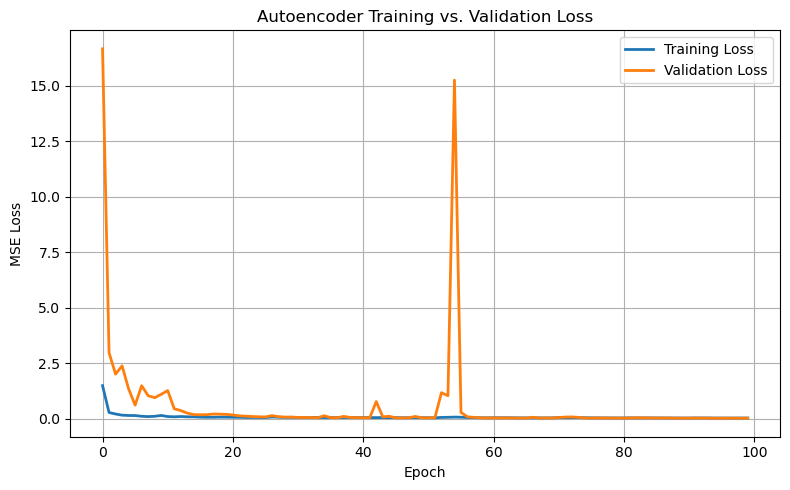

In [11]:
import matplotlib.pyplot as plt

def plot_ae_training_history(history):
    plt.figure(figsize=(8, 5))
    plt.plot(history.history['loss'], label='Training Loss', linewidth=2)
    plt.plot(history.history['val_loss'], label='Validation Loss', linewidth=2)
    plt.title('Autoencoder Training vs. Validation Loss')
    plt.xlabel('Epoch')
    plt.ylabel('MSE Loss')
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()
plot_ae_training_history(auto_history)

In [12]:
# MediaPipe-style skeleton connections (copied from your OpenCV code)
SKELETON_CONNECTIONS = [
    (0, 1), (1, 2), (2, 3), (3, 7),
    (0, 4), (4, 5), (5, 6), (6, 8),
    (9, 10),
    (11, 12),
    (11, 13), (13, 15), (15, 17),
    (15, 19), (15, 21),
    (12, 14), (14, 16), (16, 18),
    (16, 20), (16, 22),
    (11, 23), (12, 24),
    (23, 24),
    (23, 25), (25, 27), (27, 29), (29, 31),
    (24, 26), (26, 28), (28, 30), (30, 32)
]

def draw_pose(ax, coords, color='blue', title='Pose'):
    ax.set_title(title)
    ax.set_xlim(-1, 1)
    ax.set_ylim(-1, 1)
    ax.invert_yaxis()
    ax.grid(True)

    # Scatter joints
    ax.scatter(coords[:, 0], coords[:, 2], c=color)

    # Draw lines
    for start_idx, end_idx in SKELETON_CONNECTIONS:
        if start_idx < len(coords) and end_idx < len(coords):
            x_start, y_start = coords[start_idx, 0], coords[start_idx, 2]
            x_end, y_end = coords[end_idx, 0], coords[end_idx, 2]
            ax.plot([x_start, x_end], [y_start, y_end], color=color, linewidth=2)

def plot_ground_truth_vs_reconstruction(model, X, frame_index=0, sample_index=0,
                                        joint_n=33, joint_d=3):
    X_pred = model.predict(X)

    gt_pose = X[sample_index, frame_index].reshape(joint_n, joint_d)
    recon_pose = X_pred[sample_index, frame_index].reshape(joint_n, joint_d)

    gt_pose -= gt_pose.mean(axis=0)
    recon_pose -= recon_pose.mean(axis=0)

    fig, axes = plt.subplots(1, 2, figsize=(12, 5))
    draw_pose(axes[0], gt_pose, color='blue', title='Ground Truth Pose')
    draw_pose(axes[1], recon_pose, color='red', title='Reconstructed Pose')

    plt.suptitle(f"Sample {sample_index}, Frame {frame_index}")
    plt.tight_layout()
    plt.show()


2025-04-25 11:24:27.533879: W external/local_xla/xla/tsl/framework/bfc_allocator.cc:306] Allocator (GPU_0_bfc) ran out of memory trying to allocate 2.54GiB with freed_by_count=0. The caller indicates that this is not a failure, but this may mean that there could be performance gains if more memory were available.
2025-04-25 11:24:36.272382: W external/local_xla/xla/tsl/framework/bfc_allocator.cc:306] Allocator (GPU_0_bfc) ran out of memory trying to allocate 2.54GiB with freed_by_count=0. The caller indicates that this is not a failure, but this may mean that there could be performance gains if more memory were available.


14/15 ━━━━━━━━━━━━━━━━━━━━ 0s 141ms/step

2025-04-25 11:24:44.846257: E external/local_xla/xla/service/slow_operation_alarm.cc:65] Trying algorithm eng20{k2=1,k4=2,k5=1,k6=0,k7=0,k19=0} for conv (f32[10,512,64,33]{3,2,1,0}, u8[0]{0}) custom-call(f32[10,1024,64,33]{3,2,1,0}, f32[512,1024,3,3]{3,2,1,0}, f32[512]{0}), window={size=3x3 pad=1_1x1_1}, dim_labels=bf01_oi01->bf01, custom_call_target="__cudnn$convBiasActivationForward", backend_config={"cudnn_conv_backend_config":{"activation_mode":"kRelu","conv_result_scale":1,"leakyrelu_alpha":0,"side_input_scale":0},"force_earliest_schedule":false,"operation_queue_id":"0","wait_on_operation_queues":[]} is taking a while...
2025-04-25 11:24:44.875588: E external/local_xla/xla/service/slow_operation_alarm.cc:133] The operation took 2.690868163s
Trying algorithm eng20{k2=1,k4=2,k5=1,k6=0,k7=0,k19=0} for conv (f32[10,512,64,33]{3,2,1,0}, u8[0]{0}) custom-call(f32[10,1024,64,33]{3,2,1,0}, f32[512,1024,3,3]{3,2,1,0}, f32[512]{0}), window={size=3x3 pad=1_1x1_1}, dim_labels=bf01_oi01->bf01,

15/15 ━━━━━━━━━━━━━━━━━━━━ 27s 759ms/step


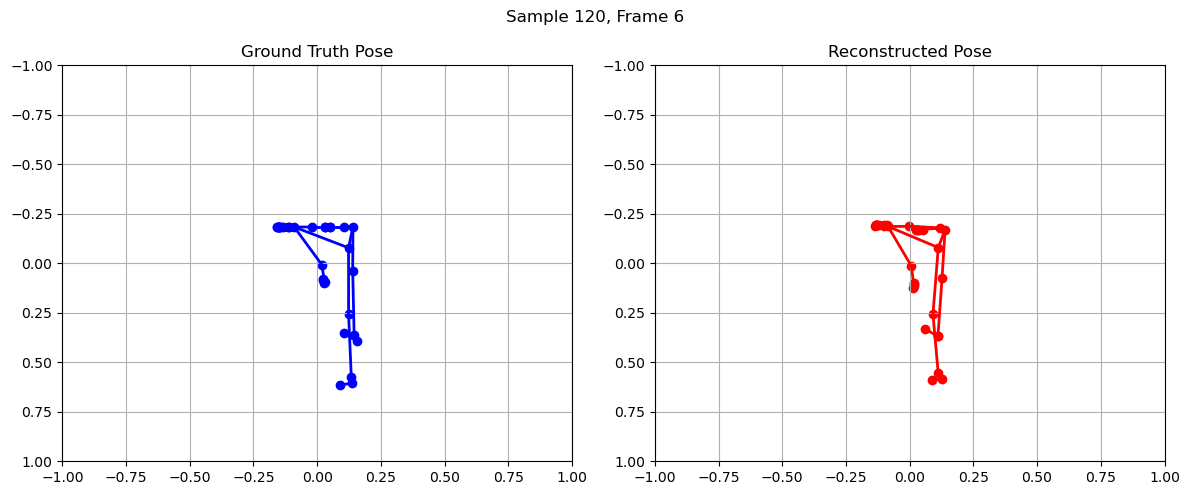

In [13]:
autoencoder = load_model("best_autoencoder.keras", compile=False)
plot_ground_truth_vs_reconstruction(autoencoder, X_data, frame_index=6, sample_index=120, joint_n=33, joint_d=3)


In [14]:
# Load Pretrained Conv2D Encoder
def build_with_pretrained_conv_encoder(frame_l, joint_n, joint_d, encoder_file):
    """Builds a feature extraction model using the correct pre-trained Conv2D encoder."""
    
    P = Input(shape=(frame_l, joint_n, joint_d))  # Shape is preserved
    encoder = load_model(encoder_file, compile=False)  # Trained Conv2D encoder

    #Freeze encoder weights (optional)
    # for layer in encoder.layers:
    #     layer.trainable = False

    encoded_features = encoder(P)
    return Model(inputs=P, outputs=encoded_features)

# Build Final Classification Model Using Conv2D Encoder
def build_stim_auto():
    # Load pretrained encoder
    full_body_model = build_with_pretrained_conv_encoder(C.frame_l, 33, 3, "conv_encoder.h5")

    # Input pose data
    P_full_input = Input(shape=(C.frame_l, 33, 3))

    # Feature extraction
    full_body_output = full_body_model(P_full_input)

    # Global pooling over time and joints
    x = GlobalMaxPool2D()(full_body_output)

    # Fully connected layers

    x = Dense(128, activation='relu')(x)
    x = Dropout(0.2)(x)
    
    x = Dense(256, activation='relu')(x)
    x = Dropout(0.2)(x)

    x = Dense(512, activation='relu')(x)
    x = Dropout(0.2)(x)
    
    x = Dense(256, activation='relu')(x)
    x = Dropout(0.2)(x)

    x = Dense(128, activation='relu')(x)
    x = Dropout(0.2)(x)

    x = Dense(27, activation='relu')(x)
    x = Dropout(0.2)(x)

    # x = Dense(9, activation='relu')(x)
    # x = Dropout(0.2)(x)

    output = Dense(C.clc, activation='softmax')(x)

    model = Model(inputs=P_full_input, outputs=output)
    return model


In [15]:
# Create and Compile the Final Model
stim_auto = build_stim_auto()
stim_auto.summary()

Model: "functional_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 64, 33, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ functional_2 (Functional)       │ (None, 64, 33, 64)     │     6,304,192 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_max_pooling2d            │ (None, 64)             │             0 │
│ (GlobalMaxPooling2D)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │         8,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_8 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 256)            │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_9 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 512)            │       131,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_10 (Dropout)            │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_11 (Dropout)            │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_12 (Dropout)            │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 27)             │         3,483 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_13 (Dropout)            │ (None, 27)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 3)              │            84 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,644,911 (25.35 MB)

 Trainable params: 6,641,071 (25.33 MB)

 Non-trainable params: 3,840 (15.00 KB)

In [16]:
def data_loader(dataset):
    data = {}
    data['pose'] = []
    data['label'] = []
    
    for i in tqdm(range(len(dataset))):
        label = dataset[i][1]
        skeletons = dataset[i][0]
        
        skeleton_path =os.path.join(C.data_dir, str(skeletons))
        
        try:
            p = np.load(skeleton_path).astype('float32')
            for j in range(p.shape[1]):
                p[:, j] = medfilt(p[:, j])
            
            data['pose'].append(p)
            data['label'].append(label)
        except Exception as e:
            print(f"An error occurred while processing {skeletons}: {e}")
            
    X = []
    Y = []
    for i in tqdm(range(len(data['pose']))):
        p = np.copy(data['pose'][i]).reshape([-1,33,3])
        if(p.shape[0]>10):
            p = zoom(p,target_l=C.frame_l,joints_num=C.joint_n,joints_dim=C.joint_d)
            p = normlize_range(p)
            # print(p)
            label = np.zeros(C.clc)
            #print(int(Train['label'][i]))
            label[int(data['label'][i])] = 1
    
            X.append(p)
            Y.append(label)

    
    return np.stack(X) , np.stack(Y)

Trian with k-fold

In [ ]:

# Define the path to the dataset info file
output_info_file =C.dataset_info # Path to dataset info

# Load dataset info
dataset_info = read_dataset_info(output_info_file)

# Group subjects per class
classwise_subjects = defaultdict(lambda: defaultdict(list))

for info in dataset_info:
    class_label = info[1]  # Class (e.g., "Spinning", "HeadBanging")
    filename = info[2]     # Extract filename
    parts = filename.split('_')
    subject_id = f"{parts[1]}_{parts[2]}"  # Unique subject identifier
    
    classwise_subjects[class_label][subject_id].append((filename, class_label))  # Store filename & label

subject_to_label = {}

# Iterate over classwise_subjects to populate subject labels
for class_label, subjects in classwise_subjects.items():
    for subject_id in subjects.keys():
        subject_to_label[subject_id] = class_label  # Assign class label to subject

# Collect unique subjects across all classes
all_subjects = list(subject_to_label.keys())  # Unique subjects
labels = [subject_to_label[subj] for subj in all_subjects]  # List of class labels
# Perform balanced train-test split for each class
random.seed(42)  # Ensure reproducibility
random.shuffle(all_subjects)

# Create subject-level KFold splits
kfold = StratifiedKFold(n_splits=C.num_folds, shuffle=False)  # No shuffle since manually shuffled

fold_results = []
y_true_pred = []
fold_histories = []

for fold, (train_subj_idx, test_subj_idx) in enumerate(kfold.split(all_subjects, labels)):
    K.clear_session() 
    print(f"\n--- Fold {fold+1}/{C.num_folds} ---")

    train_subjects = set([all_subjects[i] for i in train_subj_idx])
    test_subjects = set([all_subjects[i] for i in test_subj_idx])

    # Create train and test sets ensuring mutual exclusivity
    train_list = label_encode([vid for class_subjects in classwise_subjects.values() 
                  for subj, vids in class_subjects.items() if subj in train_subjects for vid in vids])
    test_list = label_encode([vid for class_subjects in classwise_subjects.values() 
                 for subj, vids in class_subjects.items() if subj in test_subjects for vid in vids])

    # print(train_subjects)
    # print("------------------------------------")
    # print(test_subjects)

    X, Y = data_loader(train_list)
    Xt, Yt = data_loader(test_list)


    stim_auto = build_stim_auto()
    stim_auto.compile(loss="categorical_crossentropy",optimizer=keras.optimizers.Adam(5e-3),metrics=['accuracy'])
    lrScheduler = keras.callbacks.ReduceLROnPlateau(monitor='loss', factor=0.1, patience=5, cooldown=4, min_lr=5e-3)

    checkpoint_callback = ModelCheckpoint(
        filepath=f'Autoencoder_best_model_fold_{fold+1}.keras',  # Save per fold
        monitor='val_accuracy',  # Track validation accuracy
        save_best_only=True,  # Save only the best model
        mode='max',  # Higher accuracy is better
        verbose=1
    )

    history = stim_auto.fit(X, Y,
            batch_size=16,
            epochs=256,
            verbose=True,
            shuffle=True,
            callbacks=[lrScheduler,checkpoint_callback],
            validation_data=(Xt, Yt)
            )

    fold_histories.append(history.history)

    stim_auto.load_weights(f'Autoencoder_best_model_fold_{fold+1}.keras')
    
    Y_pred = stim_auto.predict(Xt)
    labels = ['Arm Flapping', 'HeadBanging', 'Spinning']
    
    y_true = []
    for i in np.argmax(Yt,axis=1):
        y_true.append(labels[i])
    
    y_pred = []
    for i in np.argmax(Y_pred,axis=1):
        y_pred.append(labels[i])

    y_true_pred.append([y_true, y_pred, labels])
    
    # plot_confusion_matrix(y_true, y_pred, labels)
    
    accuracy = accuracy_score(y_true,y_pred)
    print("Accuracy:", accuracy)

    fold_results.append(accuracy)

# Print final results
avg_accuracy = np.mean(fold_results)
print(f"\nFinal Cross-Validation Accuracy: {avg_accuracy:.4f}")

print(fold_results)



--- Fold 1/5 ---


  0%|                                                                                           | 0/365 [00:00<?, ?it/s]/tmp/ipykernel_889069/3953159985.py:8: DeprecationWarning: Please import `zoom` from the `scipy.ndimage` namespace; the `scipy.ndimage.interpolation` namespace is deprecated and will be removed in SciPy 2.0.0.
  p_new[:,m,n] = inter.zoom(p[:,m,n],target_l/l)[:target_l]
100%|██████████████████████████████████████████████████████████████████████████████████| 95/95 [00:00<00:00, 207.80it/s]


Epoch 1/256
22/23 ━━━━━━━━━━━━━━━━━━━━ 0s 146ms/step - accuracy: 0.3500 - loss: 2.2657

2025-04-25 11:25:05.229497: W external/local_xla/xla/tsl/framework/bfc_allocator.cc:306] Allocator (GPU_0_bfc) ran out of memory trying to allocate 2.28GiB with freed_by_count=0. The caller indicates that this is not a failure, but this may mean that there could be performance gains if more memory were available.


23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 838ms/step - accuracy: 0.3490 - loss: 2.2353

2025-04-25 11:25:18.947357: I external/local_xla/xla/stream_executor/cuda/cuda_asm_compiler.cc:397] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_181', 4 bytes spill stores, 4 bytes spill loads

2025-04-25 11:25:20.021594: I external/local_xla/xla/stream_executor/cuda/cuda_asm_compiler.cc:397] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_195', 4 bytes spill stores, 4 bytes spill loads



... (5 outputs left out)

2/3 ━━━━━━━━━━━━━━━━━━━━ 0s 267ms/stepWARNING:tensorflow:6 out of the last 21 calls to <function TensorFlowTrainer.make_predict_function.<locals>.one_step_on_data_distributed at 0x7f3796182840> triggered tf.function retracing. Tracing is expensive and the excessive number of tracings could be due to (1) creating @tf.function repeatedly in a loop, (2) passing tensors with different shapes, (3) passing Python objects instead of tensors. For (1), please define your @tf.function outside of the loop. For (2), @tf.function has reduce_retracing=True option that can avoid unnecessary retracing. For (3), please refer to https://www.tensorflow.org/guide/function#controlling_retracing and https://www.tensorflow.org/api_docs/python/tf/function for  more details.


3/3 ━━━━━━━━━━━━━━━━━━━━ 2s 508ms/step
Accuracy: 0.3473684210526316

--- Fold 3/5 ---


  0%|                                                                                           | 0/370 [00:00<?, ?it/s]/tmp/ipykernel_889069/3953159985.py:8: DeprecationWarning: Please import `zoom` from the `scipy.ndimage` namespace; the `scipy.ndimage.interpolation` namespace is deprecated and will be removed in SciPy 2.0.0.
  p_new[:,m,n] = inter.zoom(p[:,m,n],target_l/l)[:target_l]
100%|██████████████████████████████████████████████████████████████████████████████████| 90/90 [00:00<00:00, 191.87it/s]


Epoch 1/256
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 280ms/step - accuracy: 0.2866 - loss: 2.4130
Epoch 1: val_accuracy improved from -inf to 0.27778, saving model to Autoencoder_best_model_fold_3.keras
23/23 ━━━━━━━━━━━━━━━━━━━━ 16s 442ms/step - accuracy: 0.2878 - loss: 2.3817 - val_accuracy: 0.2778 - val_loss: 1.1034 - learning_rate: 0.0050
Epoch 2/256
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 146ms/step - accuracy: 0.3051 - loss: 1.1188
Epoch 2: val_accuracy did not improve from 0.27778
23/23 ━━━━━━━━━━━━━━━━━━━━ 4s 158ms/step - accuracy: 0.3062 - loss: 1.1183 - val_accuracy: 0.2778 - val_loss: 1.1034 - learning_rate: 0.0050
Epoch 3/256
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 142ms/step - accuracy: 0.2925 - loss: 1.1100
Epoch 3: val_accuracy improved from 0.27778 to 0.33333, saving model to Autoencoder_best_model_fold_3.keras
23/23 ━━━━━━━━━━━━━━━━━━━━ 4s 160ms/step - accuracy: 0.2928 - loss: 1.1105 - val_accuracy: 0.3333 - val_loss: 1.1031 - learning_rate: 0.0050
Epoch 4/256
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 148ms/ste

Plot results

In [ ]:
# Initialize
conf_matrices = []
accuracies = []
weighted_accuracies = []
precisions = []
recalls = []
weighted_f1_scores = []
auc_scores = []
ioc_scores = []

num_classes = len(y_true_pred[0][2])  # from labels
all_labels = y_true_pred[0][2]        # consistent labels

# Color palette for ROC
colors = plt.cm.Set1(np.linspace(0, 1, len(y_true_pred)))

# For ROC plotting
plt.figure(figsize=(10, 7))
for fold, data in enumerate(y_true_pred):
    y_true, y_pred, labels = data

    print(f"\n--- Fold {fold+1} Evaluation ---")

    # Confusion matrix
    cm = confusion_matrix(y_true, y_pred, labels=labels)
    conf_matrices.append(cm)

    # Accuracy
    acc = accuracy_score(y_true, y_pred)
    weighted_acc = np.sum(np.diag(cm)) / np.sum(cm)
    accuracies.append(acc)
    weighted_accuracies.append(weighted_acc)

    # Precision, recall, F1
    precision = precision_score(y_true, y_pred, average='macro', zero_division=0)
    recall = recall_score(y_true, y_pred, average='macro', zero_division=0)
    weighted_f1 = f1_score(y_true, y_pred, average='weighted')

    precisions.append(precision)
    recalls.append(recall)
    weighted_f1_scores.append(weighted_f1)

    # AUC (Macro)
    try:
        y_true_bin = label_binarize(y_true, classes=labels)
        y_pred_bin = label_binarize(y_pred, classes=labels)
        auc = roc_auc_score(y_true_bin, y_pred_bin, average='macro', multi_class="ovr")
        auc_scores.append(auc)

        # Macro-average ROC (manual, since you want visualization)
        fpr, tpr, _ = roc_curve(y_true_bin.ravel(), y_pred_bin.ravel())
        plt.plot(fpr, tpr, label=f'Fold {fold+1} (AUC = {auc:.2f})', color=colors[fold])
    except ValueError:
        auc_scores.append(np.nan)

    # IoC
    ioc = 1 - acc
    ioc_scores.append(ioc)

    # Fold scores
    print(f"Accuracy: {acc:.4f}")
    print(f"Weighted Accuracy: {weighted_acc:.4f}")
    print(f"Precision: {precision:.4f}")
    print(f"Recall: {recall:.4f}")
    print(f"Weighted F1-score: {weighted_f1:.4f}")
    print(f"AUC: {auc:.4f}")
    print(f"IoC: {ioc:.4f}")

# ===== Plot 2: ROC Curve Summary =====
plt.plot([0, 1], [0, 1], 'k--', label='Chance')
plt.xlabel('False Positive Rate', fontsize=14)
plt.ylabel('True Positive Rate', fontsize=14)
plt.title('ROC Curve (Macro-average per Fold)', fontsize=16)
plt.legend(fontsize=12)
plt.grid(True)
plt.show()

# ===== Final Results =====
print("\n--- Final Cross-Validation Results ---")
print(f"Accuracy: Mean = {np.mean(accuracies):.4f}, Std = {np.std(accuracies):.4f}")
print(f"Weighted Accuracy: {np.mean(weighted_accuracies):.4f}")
print(f"Precision: {np.mean(precisions):.4f}")
print(f"Recall: {np.mean(recalls):.4f}")
print(f"Weighted F1-score: {np.mean(weighted_f1_scores):.4f}")
print(f"AUC: {np.nanmean(auc_scores):.4f}")
print(f"IoC: {np.mean(ioc_scores):.4f}")

# ===== Plot 1: Confusion Matrices =====
fig, axs = plt.subplots(2, 3, figsize=(18, 12))
axs = axs.flatten()

for i, cm in enumerate(conf_matrices):
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
                xticklabels=all_labels, yticklabels=all_labels,
                ax=axs[i], cbar=False, annot_kws={"size": 14})
    axs[i].set_title(f'Fold {i+1}', fontsize=18)
    axs[i].set_xlabel('Predicted', fontsize=16)
    axs[i].set_ylabel('True', fontsize=16)
    axs[i].tick_params(axis='both', labelsize=14)

if len(conf_matrices) < 6:
    fig.delaxes(axs[-1])

plt.tight_layout()
plt.show()

# Create 5 subplots loss functions (2 row, 3 columns)
fig, axs = plt.subplots(2,3, figsize=(18, 12))
axs = axs.flatten()
for i, hist in enumerate(fold_histories):
    epochs = range(1, len(hist['loss']) + 1)
    axs[i].plot(epochs, hist['loss'], label='Train Loss')
    axs[i].plot(epochs, hist['val_loss'], label='Val Loss')
    axs[i].set_title(f'Fold {i+1}', fontsize=14)
    axs[i].set_xlabel('Epochs')
    if i == 0:
        axs[i].set_ylabel('Loss')
    axs[i].grid(True)
    axs[i].legend()

plt.tight_layout()
plt.show()


# ===== Plot 3: Accuracy, Precision, Recall, F1 =====
folds = [f'Fold {i+1}' for i in range(len(y_true_pred))]

plt.figure(figsize=(10, 6))
plt.plot(folds, accuracies, marker='o', label='Accuracy')
plt.plot(folds, precisions, marker='s', label='Precision')
plt.plot(folds, recalls, marker='^', label='Recall')
plt.plot(folds, weighted_f1_scores, marker='d', label='F1 Score')

plt.title('Performance Metrics Across Folds', fontsize=16)
plt.xlabel('Fold', fontsize=14)
plt.ylabel('Score', fontsize=14)
plt.ylim(0.5, 1.05)
plt.grid(True)
plt.legend(fontsize=12)
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)
plt.tight_layout()
plt.show()


In [ ]:
for i, hist in enumerate(fold_histories):
    epochs = range(1, len(hist['loss']) + 1)
    
    plt.plot(epochs, hist['loss'], label='Train Loss')
    plt.plot(epochs, hist['val_loss'], label='Val Loss')
    plt.title(f'Fold {i+1}', fontsize=14)
    if i == 0:
        axs[i].set_ylabel('Loss')
    axs[i].grid(True)
    axs[i].legend()
    
    plt.xlabel('Epochs', fontsize=14)
    plt.ylabel('Loss', fontsize=14)
    plt.legend(fontsize=12)
    plt.grid(True)
    plt.tight_layout()
    plt.show()

Model inference time 

In [ ]:
# Define the model and input shape
model_dict = {
    "stim_auto": {
        "model": stim_auto,  # Replace with your actual model variable
        "input_shape": (1, 64, 33, 3),
    }
}

def measure_inference_time(model, input_shape, runs=100):
    dummy_input = np.random.randn(*input_shape).astype(np.float32)

    # Warm-up
    model.predict(dummy_input)

    # Timed runs
    start = time.time()
    for _ in range(runs):
        model.predict(dummy_input)
    end = time.time()

    return ((end - start) / runs) * 1000  # milliseconds

def get_model_stats(model, save_path="temp_model.keras"):
    model.save(save_path, include_optimizer=False)
    size_mb = os.path.getsize(save_path) / (1024 * 1024)
    os.remove(save_path)
    param_count = model.count_params()
    return param_count, round(size_mb, 2)

# Run evaluation
results = []

for model_name, info in model_dict.items():
    try:
        model = info["model"]
        input_shape = info["input_shape"]

        inf_time = measure_inference_time(model, input_shape)
        params, size_mb = get_model_stats(model)

        results.append({
            "Model": model_name,
            "Parameters": params,
            "Model Size (MB)": size_mb,
            "Inference Time (ms)": round(inf_time, 2)
        })

    except Exception as e:
        results.append({
            "Model": model_name,
            "Parameters": "Error",
            "Model Size (MB)": "Error",
            "Inference Time (ms)": f"Failed: {str(e)}"
        })

# Output
df = pd.DataFrame(results)
df.to_csv("single_input_model_timing_report.csv", index=False)
print(df)